# ML Honors Assignment - 5

**Name:** Vaishnav Mankar

**Rollno:** 41252

---

**Problem Statement:** Exploratory analysis on Twitter text data. Perform text pre-processing, apply Zipf's and Heaps' law, identify topics.

**Dataset:** Twitter US Airline Sentiment (Kaggle — `Tweets.csv`)

**Requirements:** Python 3, NumPy, Pandas, Scikit-Learn, Matplotlib

**Code:-**

In [1]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer

df = pd.read_csv("data/Tweets.csv")
tweets = df["text"]
print("Tweets:", len(tweets))
print(df["airline_sentiment"].value_counts())
print(f"Average length: {tweets.str.len().mean():.0f} characters, {tweets.str.split().str.len().mean():.1f} words")
display(df[["airline", "airline_sentiment", "text"]].head())

Tweets: 14640
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64
Average length: 104 characters, 17.7 words


,airline,airline_sentiment,text
0,Virgin America,neutral,@VirginAmerica What @dhepburn said.
1,Virgin America,positive,@VirginAmerica plus you've added commercials t...
2,Virgin America,neutral,@VirginAmerica I didn't today... Must mean I n...
3,Virgin America,negative,@VirginAmerica it's really aggressive to blast...
4,Virgin America,negative,@VirginAmerica and it's a really big bad thing...


In [2]:
def preprocess(text):
    text = re.sub(r"http\S+|@\w+", " ", text.lower())
    return re.sub(r"[^a-z\s]", " ", text).split()


tokens = tweets.apply(preprocess)
print("Original:", tweets.iloc[0])
print("Cleaned :", " ".join(tokens.iloc[0]))

all_words = [w for t in tokens for w in t]
filtered = [w for w in all_words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
print(f"\nWords: {len(all_words)} -> {len(filtered)} after removing stop words")
print("Top 10 words:", Counter(filtered).most_common(10))

Original: @VirginAmerica What @dhepburn said.
Cleaned : what said

Words: 241115 -> 110392 after removing stop words
Top 10 words: [('flight', 3958), ('thanks', 1083), ('cancelled', 1065), ('just', 974), ('service', 967), ('help', 873), ('time', 794), ('customer', 758), ('hours', 684), ('amp', 683)]


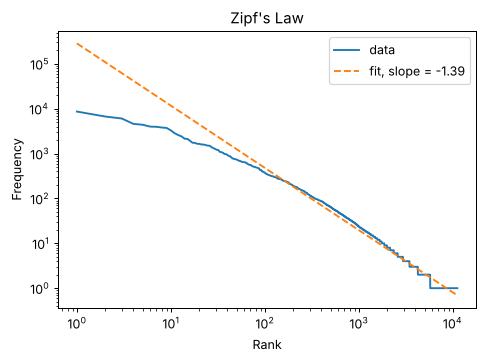

Log-log slope = -1.39


In [3]:
freqs = np.array(sorted(Counter(all_words).values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
slope, intercept = np.polyfit(np.log(ranks), np.log(freqs), 1)

plt.figure(figsize=(6, 4))
plt.loglog(ranks, freqs, label="data")
plt.loglog(ranks, np.exp(intercept) * ranks ** slope, "--", label=f"fit, slope = {slope:.2f}")
plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.title("Zipf's Law")
plt.legend()
plt.show()
print(f"Log-log slope = {slope:.2f}")

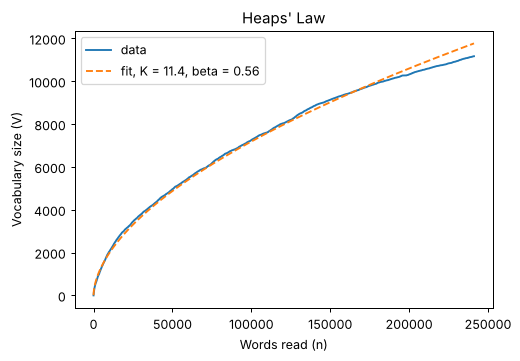

V = K * n^beta with K = 11.4 and beta = 0.56


In [4]:
seen, vocab_size = set(), []
for word in all_words:
    seen.add(word)
    vocab_size.append(len(seen))
n = np.arange(1, len(all_words) + 1)
beta, log_k = np.polyfit(np.log(n), np.log(vocab_size), 1)

plt.figure(figsize=(6, 4))
plt.plot(n, vocab_size, label="data")
plt.plot(n, np.exp(log_k) * n ** beta, "--", label=f"fit, K = {np.exp(log_k):.1f}, beta = {beta:.2f}")
plt.xlabel("Words read (n)")
plt.ylabel("Vocabulary size (V)")
plt.title("Heaps' Law")
plt.legend()
plt.show()
print(f"V = K * n^beta with K = {np.exp(log_k):.1f} and beta = {beta:.2f}")

In [5]:
vectorizer = CountVectorizer(stop_words="english", min_df=5, max_df=0.5, token_pattern=r"[a-z]{3,}")
counts = vectorizer.fit_transform(" ".join(t) for t in tokens)
lda = LatentDirichletAllocation(n_components=5, random_state=42).fit(counts)
vocab = vectorizer.get_feature_names_out()
for i, weights in enumerate(lda.components_):
    print(f"Topic {i + 1}: {', '.join(vocab[weights.argsort()[::-1][:8]])}")

Topic 1: flight, bag, ticket, yes, help, check, got, need
Topic 2: hold, amp, phone, time, wait, lost, help, hours
Topic 3: flight, cancelled, flights, flightled, delayed, thanks, help, tomorrow
Topic 4: flight, plane, gate, late, crew, problems, sitting, just
Topic 5: service, customer, thank, airline, just, like, guys, thanks
